In [1]:
!pip install -q rdkit scikit-learn scipy xgboost lightgbm



[notice] A new release of pip is available: 23.3.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


In [3]:
%pip install matplotlib seaborn

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
Note: you may need to restart the kernel to use updated packages.


In [4]:

import sys
import os
import warnings
import pickle

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem, RDLogger
from rdkit.Chem import (
    Descriptors,
    rdFingerprintGenerator,
    MACCSkeys
)
from rdkit.Chem.Scaffolds import MurckoScaffold

from sklearn.model_selection import KFold
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from scipy.stats import pearsonr, spearmanr

RDLogger.DisableLog("rdApp.*")

RANDOM_STATE = 0

import rdkit
import sklearn

print("Python:", sys.version.split()[0])
print("RDKit:", rdkit.__version__)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

print("\nEnvironment ready!")


Python: 3.11.18
RDKit: 2026.03.6
Scikit-learn: 1.9.1
NumPy: 2.4.6
Pandas: 3.1.1

Environment ready!


In [5]:

# ==========================================
# STEP 2: LOAD USP5 DATASET
# ==========================================

CSV_URL = (
    "https://raw.githubusercontent.com/"
    "devitanuraljazira/Model-ML-DL/refs/heads/main/"
    "USP5_Kd_80_fixed.csv"
)

df = pd.read_csv(CSV_URL)

df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


Dataset shape: (80, 3)
Columns: ['Molecule ChEMBL ID', 'Smiles', 'pKd']


,Molecule ChEMBL ID,Smiles,pKd
0,CHEMBL5285743,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057
1,CHEMBL4451435,O=C(O)CCc1nnc(-c2ccc(Cl)cc2)o1,3.346787
2,CHEMBL5290717,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.346787
3,CHEMBL5285627,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,4.638272
4,CHEMBL5274675,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.102373


In [6]:

# ==========================================
# STEP 3: VALIDATE DATASET
# ==========================================

df["mol"] = df["Smiles"].apply(Chem.MolFromSmiles)

y = df["pKd"].to_numpy(dtype=float)

print("Total compounds:", len(df))
print("Valid SMILES:", df["mol"].notna().sum())
print("Unique SMILES:", df["Smiles"].nunique())
print("Missing pKd:", df["pKd"].isna().sum())

assert len(df) == 80
assert df["mol"].notna().all()
assert df["pKd"].notna().all()

print("\nDataset validation successful!")


Total compounds: 80
Valid SMILES: 80
Unique SMILES: 80
Missing pKd: 0

Dataset validation successful!


In [7]:

# ==========================================
# STEP 4: RANDOM 5-FOLD SPLIT
# ==========================================

import numpy as np
import pandas as pd
from sklearn.model_selection import KFold

SEED = 100
N_SPLITS = 5

kf = KFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

folds = list(kf.split(df))

print("Random 5-Fold Cross-Validation")
print("Seed:", SEED)
print("Total compounds:", len(df))
print("=" * 50)

for fold_number, (train_idx, test_idx) in enumerate(folds, start=1):

    train_data = df.iloc[train_idx].copy()
    test_data = df.iloc[test_idx].copy()

    print(f"\nFold {fold_number}")
    print("Training compounds:", len(train_data))
    print("Testing compounds:", len(test_data))

    print("\nTraining data:")
    display(train_data[["Molecule ChEMBL ID", "pKd"]].head())

    print("Testing data:")
    display(test_data[["Molecule ChEMBL ID", "pKd"]].head())


Random 5-Fold Cross-Validation
Seed: 100
Total compounds: 80

Fold 1
Training compounds: 64
Testing compounds: 16

Training data:


,Molecule ChEMBL ID,pKd
0,CHEMBL5285743,3.886057
1,CHEMBL4451435,3.346787
2,CHEMBL5290717,4.346787
3,CHEMBL5285627,4.638272
4,CHEMBL5274675,4.102373


Testing data:


,Molecule ChEMBL ID,pKd
5,CHEMBL5276984,3.823909
6,CHEMBL5278336,5.552842
11,CHEMBL4455129,3.602060
20,CHEMBL5277702,4.721246
23,CHEMBL4474814,4.283997



Fold 2
Training compounds: 64
Testing compounds: 16

Training data:


,Molecule ChEMBL ID,pKd
0,CHEMBL5285743,3.886057
1,CHEMBL4451435,3.346787
2,CHEMBL5290717,4.346787
3,CHEMBL5285627,4.638272
4,CHEMBL5274675,4.102373


... (10 outputs left out)


Fold 5
Training compounds: 64
Testing compounds: 16

Training data:


,Molecule ChEMBL ID,pKd
0,CHEMBL5285743,3.886057
1,CHEMBL4451435,3.346787
2,CHEMBL5290717,4.346787
3,CHEMBL5285627,4.638272
4,CHEMBL5274675,4.102373


Testing data:


,Molecule ChEMBL ID,pKd
8,CHEMBL5410606,5.346787
9,CHEMBL4442518,3.431798
10,CHEMBL4463491,3.075721
14,CHEMBL4440506,4.096910
15,CHEMBL5286035,4.327902


In [ ]:

# ==========================================
# STEP 5: SAVE TRAINING AND TEST DATA
# ==========================================

import os

OUTPUT_DIR = "USP5_Random_5Fold_Seed100"
os.makedirs(OUTPUT_DIR, exist_ok=True)

summary = []

for fold_number, (train_idx, test_idx) in enumerate(folds, start=1):

    train_data = df.iloc[train_idx].copy()
    test_data = df.iloc[test_idx].copy()

    fold_dir = os.path.join(
        OUTPUT_DIR,
        f"Fold{fold_number}"
    )

    os.makedirs(fold_dir, exist_ok=True)

    train_data.drop(columns=["mol"]).to_csv(
        os.path.join(fold_dir, "train.csv"),
        index=False
    )

    test_data.drop(columns=["mol"]).to_csv(
        os.path.join(fold_dir, "test.csv"),
        index=False
    )

    summary.append({
        "Fold": fold_number,
        "Training": len(train_data),
        "Testing": len(test_data),
        "Train_IDs": ", ".join(train_data["Molecule ChEMBL ID"]),
        "Test_IDs": ", ".join(test_data["Molecule ChEMBL ID"])
    })

summary_df = pd.DataFrame(summary)

summary_df.to_csv(
    os.path.join(OUTPUT_DIR, "fold_summary.csv"),
    index=False
)

display(summary_df[["Fold", "Training", "Testing"]])

print("Files saved in:", os.path.abspath(OUTPUT_DIR))


In [8]:

import os

# Main experiment directory
OUTPUT_DIR = "/data/Zira/Chemprop_Kd_80/Tanimoto_SVR"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Output directory:", OUTPUT_DIR)
print("Directory exists:", os.path.exists(OUTPUT_DIR))
print("Directory writable:", os.access(OUTPUT_DIR, os.W_OK))


Output directory: /data/Zira/Chemprop_Kd_80/Tanimoto_SVR
Directory exists: True
Directory writable: True


In [10]:

# ==========================================
# SAVE RANDOM 5-FOLD DATA
# ==========================================

summary = []

for fold_number, (train_idx, test_idx) in enumerate(folds, start=1):

    train_data = df.iloc[train_idx].drop(columns=["mol"]).copy()
    test_data = df.iloc[test_idx].drop(columns=["mol"]).copy()

    fold_dir = os.path.join(
        OUTPUT_DIR,
        f"Fold{fold_number}"
    )

    os.makedirs(fold_dir, exist_ok=True)

    train_data.to_csv(
        os.path.join(fold_dir, "train.csv"),
        index=False
    )

    test_data.to_csv(
        os.path.join(fold_dir, "test.csv"),
        index=False
    )

    summary.append({
        "Fold": fold_number,
        "Training": len(train_data),
        "Testing": len(test_data)
    })

summary_df = pd.DataFrame(summary)

summary_df.to_csv(
    os.path.join(OUTPUT_DIR, "fold_summary.csv"),
    index=False
)

display(summary_df)

print("\nAll fold data successfully saved!")
print("Location:", OUTPUT_DIR)


,Fold,Training,Testing
0,1,64,16
1,2,64,16
2,3,64,16
3,4,64,16
4,5,64,16



All fold data successfully saved!
Location: /data/Zira/Chemprop_Kd_80/Tanimoto_SVR


In [11]:

# ==========================================
# STEP 7: GENERATE MOLECULAR FINGERPRINTS
# ==========================================

from rdkit.Chem import AllChem, MACCSkeys
import numpy as np

# Morgan Fingerprint
morgan_fp = [
    AllChem.GetMorganFingerprintAsBitVect(
        mol,
        radius=2,
        nBits=1024
    )
    for mol in df["mol"]
]

X_morgan = np.array(morgan_fp, dtype=np.uint8)

# MACCS Fingerprint
maccs_fp = [
    MACCSkeys.GenMACCSKeys(mol)
    for mol in df["mol"]
]

X_maccs = np.array(maccs_fp, dtype=np.uint8)

print("Morgan fingerprint shape:", X_morgan.shape)
print("MACCS fingerprint shape:", X_maccs.shape)
print("Fingerprint generation completed!")


Morgan fingerprint shape: (80, 1024)
MACCS fingerprint shape: (80, 167)
Fingerprint generation completed!


In [12]:

# ==========================================
# STEP 8: FINGERPRINT FEATURE SELECTION
# ==========================================

# Morgan feature selection
morgan_frequency = X_morgan.sum(axis=0)
FP_MASK = morgan_frequency >= 4

X_morgan_selected = X_morgan[:, FP_MASK]

# MACCS feature selection
maccs_std = X_maccs.std(axis=0)
MACCS_MASK = maccs_std > 0

X_maccs_selected = X_maccs[:, MACCS_MASK]

print("Original Morgan features:", X_morgan.shape[1])
print("Selected Morgan features:", FP_MASK.sum())

print("\nOriginal MACCS features:", X_maccs.shape[1])
print("Selected MACCS features:", MACCS_MASK.sum())

# Combine Morgan and MACCS
X_FPM = np.concatenate(
    [X_morgan_selected, X_maccs_selected],
    axis=1
)

print("\nCombined FPM shape:", X_FPM.shape)


Original Morgan features: 1024
Selected Morgan features: 137

Original MACCS features: 167
Selected MACCS features: 121

Combined FPM shape: (80, 258)


In [13]:

# ==========================================
# STEP 9: SAVE FINGERPRINT FEATURES
# ==========================================

np.save(
    os.path.join(OUTPUT_DIR, "FP_MASK.npy"),
    FP_MASK
)

np.save(
    os.path.join(OUTPUT_DIR, "MACCS_MASK.npy"),
    MACCS_MASK
)

np.save(
    os.path.join(OUTPUT_DIR, "X_FPM.npy"),
    X_FPM
)

np.save(
    os.path.join(OUTPUT_DIR, "y_pKd.npy"),
    y
)

print("Fingerprint features saved successfully!")
print("Location:", OUTPUT_DIR)


Fingerprint features saved successfully!
Location: /data/Zira/Chemprop_Kd_80/Tanimoto_SVR


In [14]:

# ==========================================
# STEP 10: TANIMOTO KERNEL
# ==========================================

def tanimoto_kernel(A, B):
    inter = A @ B.T

    a = (A * A).sum(axis=1)[:, None]
    b = (B * B).sum(axis=1)[None, :]

    return inter / (a + b - inter + 1e-12)


# Test kernel matrix
K_test = tanimoto_kernel(X_FPM, X_FPM)

print("Kernel matrix shape:", K_test.shape)
print("Minimum similarity:", K_test.min())
print("Maximum similarity:", K_test.max())
print("Diagonal values:", np.diag(K_test)[:5])


Kernel matrix shape: (80, 80)
Minimum similarity: 0.11290322580645071
Maximum similarity: 0.9999999999999916
Diagonal values: [1. 1. 1. 1. 1.]


In [15]:

# ==========================================
# STEP 11: TANIMOTO SVR MODEL
# ==========================================

from sklearn.svm import SVR
from sklearn.base import BaseEstimator, RegressorMixin

class TanimotoSVR(BaseEstimator, RegressorMixin):

    def __init__(self, C=5.0, epsilon=0.05):
        self.C = C
        self.epsilon = epsilon

    def fit(self, X, y):
        self.X_ = X.copy()

        K_train = tanimoto_kernel(X, X)

        self.model_ = SVR(
            kernel="precomputed",
            C=self.C,
            epsilon=self.epsilon
        )

        self.model_.fit(K_train, y)

        return self

    def predict(self, X):
        K_test = tanimoto_kernel(X, self.X_)
        return self.model_.predict(K_test)


# Test model on all 80 compounds
model_test = TanimotoSVR(C=5.0, epsilon=0.05)

model_test.fit(X_FPM, y)

pred_test = model_test.predict(X_FPM)

print("Tanimoto SVR model created successfully!")
print("C:", model_test.C)
print("Epsilon:", model_test.epsilon)
print("Number of predictions:", len(pred_test))
print("First 5 predictions:", pred_test[:5])


Tanimoto SVR model created successfully!
C: 5.0
Epsilon: 0.05
Number of predictions: 80
First 5 predictions: [3.93454222 3.39663072 4.29673615 4.65616283 4.27037786]


In [20]:

# ==========================================
# STEP 12: RANDOM 5-FOLD CV: 5 SEEDS
# ==========================================

SEEDS = [100, 101, 102, 103, 104]

all_seed_results = []

for seed in SEEDS:

    kf_seed = KFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    for fold_number, (train_idx, test_idx) in enumerate(
        kf_seed.split(X_FPM), start=1
    ):

        model = TanimotoSVR(C=5.0, epsilon=0.05)

        model.fit(X_FPM[train_idx], y[train_idx])

        y_pred = model.predict(X_FPM[test_idx])

        all_seed_results.append({
            "Seed": seed,
            "Fold": fold_number,
            "R2": r2_score(y[test_idx], y_pred),
            "RMSE": np.sqrt(
                mean_squared_error(y[test_idx], y_pred)
            ),
            "MAE": mean_absolute_error(y[test_idx], y_pred)
        })

results_5seeds = pd.DataFrame(all_seed_results)

display(results_5seeds)

# Summary per seed
seed_summary = results_5seeds.groupby("Seed")[
    ["R2", "RMSE", "MAE"]
].mean()

display(seed_summary)

# Overall mean and standard deviation
print("\nOVERALL RESULTS: 5 SEEDS x 5 FOLDS")

display(
    seed_summary.agg(["mean", "std"])
)

# Save results
results_5seeds.to_csv(
    os.path.join(OUTPUT_DIR, "random_5fold_5seeds_all_results.csv"),
    index=False
)

seed_summary.to_csv(
    os.path.join(OUTPUT_DIR, "random_5fold_5seeds_summary.csv")
)

print("Results saved:", OUTPUT_DIR)


,Seed,Fold,R2,RMSE,MAE
0,100,1,0.748290,0.329714,0.254415
1,100,2,0.695938,0.306731,0.223517
2,100,3,0.795383,0.255993,0.205526
3,100,4,0.800030,0.293245,0.247095
4,100,5,0.188985,0.617387,0.462294
5,101,1,0.824368,0.290274,0.236068
6,101,2,0.560864,0.413715,0.315027
7,101,3,0.693921,0.252650,0.196305
8,101,4,0.856024,0.284280,0.217356
9,101,5,0.484756,0.386587,0.316724


,R2,RMSE,MAE
Seed,,,
100,0.645725,0.360614,0.278569
101,0.683987,0.325501,0.256296
102,0.698559,0.319238,0.250938
103,0.704538,0.326739,0.262926
104,0.657781,0.348352,0.274383



OVERALL RESULTS: 5 SEEDS x 5 FOLDS


,R2,RMSE,MAE
mean,0.678118,0.336089,0.264623
std,0.025560,0.017574,0.011718


Results saved: /data/Zira/Chemprop_Kd_80/Tanimoto_SVR


In [21]:

# ==========================================
# STEP 13: OOF-BASED EVALUATION
# ==========================================

SEEDS = [100, 101, 102, 103, 104]

oof_seed_results = []
all_oof_predictions = {}

for seed in SEEDS:

    kf = KFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    oof_pred = np.zeros(len(y))

    for train_idx, test_idx in kf.split(X_FPM):

        model = TanimotoSVR(C=5.0, epsilon=0.05)

        model.fit(
            X_FPM[train_idx],
            y[train_idx]
        )

        oof_pred[test_idx] = model.predict(
            X_FPM[test_idx]
        )

    all_oof_predictions[seed] = oof_pred

    oof_seed_results.append({
        "Seed": seed,
        "R2": r2_score(y, oof_pred),
        "RMSE": np.sqrt(mean_squared_error(y, oof_pred)),
        "MAE": mean_absolute_error(y, oof_pred)
    })

oof_results_df = pd.DataFrame(oof_seed_results)

display(oof_results_df)

print("\nMEAN AND STANDARD DEVIATION")

display(
    oof_results_df[["R2", "RMSE", "MAE"]].agg(["mean", "std"])
)

# Save results
oof_results_df.to_csv(
    os.path.join(OUTPUT_DIR, "random_5fold_OOF_5seeds.csv"),
    index=False
)

print("\nOOF evaluation saved successfully!")


,Seed,R2,RMSE,MAE
0,100,0.632041,0.383533,0.278569
1,101,0.725081,0.331517,0.256296
2,102,0.737231,0.324108,0.250938
3,103,0.722223,0.333235,0.262926
4,104,0.687327,0.353547,0.274383



MEAN AND STANDARD DEVIATION


,R2,RMSE,MAE
mean,0.700781,0.345188,0.264623
std,0.042676,0.024054,0.011718



OOF evaluation saved successfully!


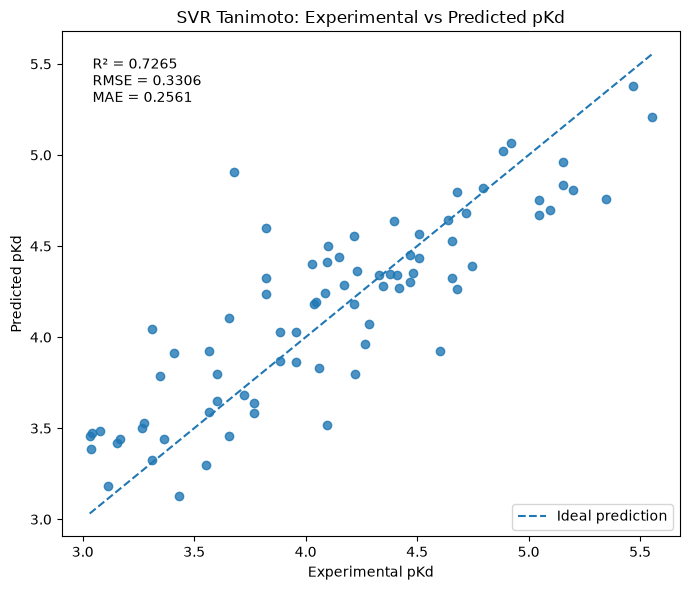

R2: 0.7265
RMSE: 0.3306
MAE: 0.2561
Plot saved successfully!


In [22]:

# ==========================================
# STEP 14: OOF PREDICTION VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt

# Average OOF predictions across five seeds
oof_matrix = np.column_stack([
    all_oof_predictions[seed]
    for seed in SEEDS
])

mean_oof_pred = oof_matrix.mean(axis=1)

# Calculate metrics
r2 = r2_score(y, mean_oof_pred)
rmse = np.sqrt(mean_squared_error(y, mean_oof_pred))
mae = mean_absolute_error(y, mean_oof_pred)

# Create plot
plt.figure(figsize=(7, 6))

plt.scatter(
    y,
    mean_oof_pred,
    alpha=0.8
)

# Ideal prediction line
min_val = min(y.min(), mean_oof_pred.min())
max_val = max(y.max(), mean_oof_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    label="Ideal prediction"
)

plt.xlabel("Experimental pKd")
plt.ylabel("Predicted pKd")

plt.title("SVR Tanimoto: Experimental vs Predicted pKd")

plt.text(
    0.05, 0.95,
    f"R² = {r2:.4f}\nRMSE = {rmse:.4f}\nMAE = {mae:.4f}",
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

plt.legend()
plt.tight_layout()

# Save figure
plt.savefig(
    os.path.join(OUTPUT_DIR, "OOF_Predicted_vs_Experimental.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("R2:", round(r2, 4))
print("RMSE:", round(rmse, 4))
print("MAE:", round(mae, 4))
print("Plot saved successfully!")


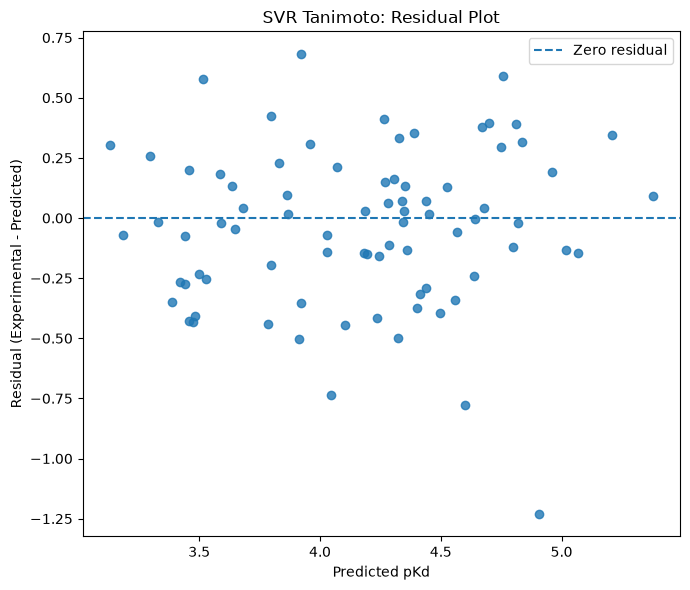

Residual Mean: -0.039636517027846235
Residual SD: 0.32824644448772217
Minimum Residual: -1.2286455197268724
Maximum Residual: 0.6807819856439119

Residual plot saved successfully!


In [23]:

# ==========================================
# STEP 15: RESIDUAL ANALYSIS
# ==========================================

import matplotlib.pyplot as plt
import numpy as np
import os

# Calculate residuals
residuals = y - mean_oof_pred

# Create residual plot
plt.figure(figsize=(7, 6))

plt.scatter(
    mean_oof_pred,
    residuals,
    alpha=0.8
)

plt.axhline(
    y=0,
    linestyle="--",
    label="Zero residual"
)

plt.xlabel("Predicted pKd")
plt.ylabel("Residual (Experimental - Predicted)")
plt.title("SVR Tanimoto: Residual Plot")

plt.legend()
plt.tight_layout()

# Save figure
plt.savefig(
    os.path.join(OUTPUT_DIR, "Residual_Plot.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Residual statistics
print("Residual Mean:", np.mean(residuals))
print("Residual SD:", np.std(residuals))
print("Minimum Residual:", np.min(residuals))
print("Maximum Residual:", np.max(residuals))

print("\nResidual plot saved successfully!")


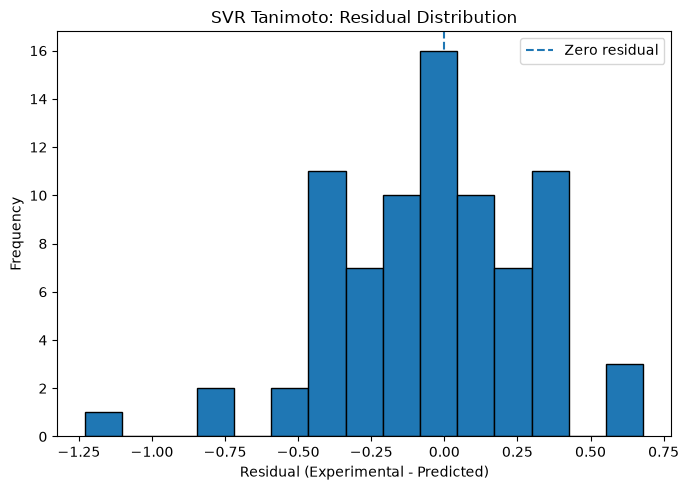

Residual mean: -0.039636517027846235
Residual median: -0.019006472305052258
Residual SD: 0.32824644448772217

Histogram saved successfully!


In [24]:

# ==========================================
# STEP 16: RESIDUAL DISTRIBUTION
# ==========================================

import matplotlib.pyplot as plt
import numpy as np
import os

plt.figure(figsize=(7, 5))

plt.hist(
    residuals,
    bins=15,
    edgecolor="black"
)

plt.axvline(
    x=0,
    linestyle="--",
    label="Zero residual"
)

plt.xlabel("Residual (Experimental - Predicted)")
plt.ylabel("Frequency")
plt.title("SVR Tanimoto: Residual Distribution")

plt.legend()
plt.tight_layout()

# Save histogram
plt.savefig(
    os.path.join(OUTPUT_DIR, "Residual_Distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Residual mean:", np.mean(residuals))
print("Residual median:", np.median(residuals))
print("Residual SD:", np.std(residuals))

print("\nHistogram saved successfully!")


In [25]:

# ==========================================
# STEP 17: LARGEST PREDICTION ERRORS
# ==========================================

error_df = df[
    ["Molecule ChEMBL ID", "Smiles", "pKd"]
].copy()

error_df["Predicted_pKd"] = mean_oof_pred
error_df["Residual"] = y - mean_oof_pred
error_df["Absolute_Error"] = np.abs(error_df["Residual"])

# Sort by absolute error
error_df = error_df.sort_values(
    by="Absolute_Error",
    ascending=False
)

# Display top 10 compounds
top_10_errors = error_df.head(10)

display(top_10_errors)

# Save results
top_10_errors.to_csv(
    os.path.join(OUTPUT_DIR, "Top_10_Prediction_Errors.csv"),
    index=False
)

print("Top 10 prediction errors saved successfully!")


,Molecule ChEMBL ID,Smiles,pKd,Predicted_pKd,Residual,Absolute_Error
24,CHEMBL5286558,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,3.677781,4.906426,-1.228646,1.228646
5,CHEMBL5276984,Cn1cc(S(=O)(=O)N2CCC(c3ccccc3)CC2)cc1C(=O)NCC(...,3.823909,4.599714,-0.775806,0.775806
12,CHEMBL4446091,Cc1cccc2c(=O)n(CC(=O)O)cnc12,3.309804,4.043924,-0.734121,0.734121
51,CHEMBL5268432,CN1CCC2(CC1)CCN(S(=O)(=O)c1ccc(C(=O)NCC(=O)O)c...,4.602060,3.921278,0.680782,0.680782
8,CHEMBL5410606,COc1ccccc1CNC(=O)Cn1c(CCC(=O)O)nc2c(Cl)cccc2c1=O,5.346787,4.755913,0.590875,0.590875
14,CHEMBL4440506,CC(C)c1ccc(C(=O)CCC(=O)O)cc1,4.096910,3.516956,0.579954,0.579954
22,CHEMBL4577714,CC(C)Cc1ccc(C(=O)CCC(=O)O)cc1,3.408935,3.912504,-0.503569,0.503569
64,CHEMBL5282333,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCN(c3ccccc3)CC2...,3.823909,4.322339,-0.498431,0.498431
75,CHEMBL5274321,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC3(CC2)OCc2ccc...,3.657577,4.103872,-0.446294,0.446294
1,CHEMBL4451435,O=C(O)CCc1nnc(-c2ccc(Cl)cc2)o1,3.346787,3.786137,-0.439349,0.439349


Top 10 prediction errors saved successfully!


In [26]:

# ==========================================
# STEP 18: CORRELATION ANALYSIS
# ==========================================

from scipy.stats import pearsonr, spearmanr

# Pearson correlation
pearson_r, pearson_p = pearsonr(y, mean_oof_pred)

# Spearman correlation
spearman_r, spearman_p = spearmanr(y, mean_oof_pred)

correlation_results = pd.DataFrame({
    "Method": ["Pearson", "Spearman"],
    "Correlation": [pearson_r, spearman_r],
    "P_value": [pearson_p, spearman_p]
})

display(correlation_results)

# Save results
correlation_results.to_csv(
    os.path.join(OUTPUT_DIR, "Correlation_Analysis.csv"),
    index=False
)

print("Correlation analysis saved successfully!")


,Method,Correlation,P_value
0,Pearson,0.855245,5.659131e-24
1,Spearman,0.845043,6.576760e-23


Correlation analysis saved successfully!


In [27]:

# ==========================================
# STEP 19: FINAL MODEL PERFORMANCE SUMMARY
# ==========================================

final_summary = pd.DataFrame({
    "Metric": [
        "R2",
        "RMSE",
        "MAE",
        "Pearson Correlation",
        "Spearman Correlation"
    ],
    "Value": [
        r2_score(y, mean_oof_pred),
        np.sqrt(mean_squared_error(y, mean_oof_pred)),
        mean_absolute_error(y, mean_oof_pred),
        pearson_r,
        spearman_r
    ]
})

display(final_summary)

final_summary.to_csv(
    os.path.join(OUTPUT_DIR, "Final_Model_Summary.csv"),
    index=False
)

print("Final evaluation summary saved!")
print("Directory:", OUTPUT_DIR)


,Metric,Value
0,R2,0.726548
1,RMSE,0.330631
2,MAE,0.256068
3,Pearson Correlation,0.855245
4,Spearman Correlation,0.845043


Final evaluation summary saved!
Directory: /data/Zira/Chemprop_Kd_80/Tanimoto_SVR


In [28]:

# ==========================================
# STEP 20: TRAIN FINAL TANIMOTO SVR MODEL
# ==========================================

final_model = TanimotoSVR(
    C=5.0,
    epsilon=0.05
)

final_model.fit(X_FPM, y)

print("Final SVR Tanimoto model trained!")
print("Training compounds:", len(y))
print("Fingerprint features:", X_FPM.shape[1])

# Save model
import joblib

joblib.dump(
    final_model,
    os.path.join(OUTPUT_DIR, "Final_Tanimoto_SVR.pkl")
)

print("\nFinal model saved successfully!")
print("Location:", OUTPUT_DIR)


Final SVR Tanimoto model trained!
Training compounds: 80
Fingerprint features: 258

Final model saved successfully!
Location: /data/Zira/Chemprop_Kd_80/Tanimoto_SVR


In [29]:

# ==========================================
# STEP 21: LOAD SCREENING DATASET
# ==========================================

SCREENING_URL = (
    "https://raw.githubusercontent.com/"
    "devitanuraljazira/USP5/refs/heads/main/"
    "hasil%20skrining.csv"
)

screen_df = pd.read_csv(SCREENING_URL)

screen_df.columns = screen_df.columns.str.strip()

print("Screening dataset shape:", screen_df.shape)
print("\nColumns:")
print(screen_df.columns.tolist())

display(screen_df.head())

print("\nDataset loaded successfully!")


Screening dataset shape: (991, 9)

Columns:
['Compound ChEMBL ID', 'Smiles', 'Smiles (RDKit Mol)', 'SlogP', 'TPSA', 'ExactMW', 'NumHBD', 'NumHBA', 'Lipinski_RO5']


,Compound ChEMBL ID,Smiles,Smiles (RDKit Mol),SlogP,TPSA,ExactMW,NumHBD,NumHBA,Lipinski_RO5
0,CHEMBL151562,C/N=C(\N)c1ccc(/C=C2/CCCC/C(=C/c3ccc(C(=N)N)cc...,C/N=C(\N)c1ccc(/C=C2/CCCC/C(=C/c3ccc(C(=N)N)cc...,3.91587,105.32,386.210661,3,3,Pass
1,CHEMBL1630638,O=C1/C(=C/c2ccc(N3CCOCC3)cc2)CC/C1=C\c1ccc(N2C...,O=C1/C(=C/c2ccc(N3CCOCC3)cc2)CC/C1=C\c1ccc(N2C...,4.18970,42.01,430.225643,0,5,Pass
2,CHEMBL150612,N=C(N)c1ccc(/C=C2/CC(c3ccccc3)C/C(=C\c3ccc(C(=...,N=C(N)c1ccc(/C=C2/CC(c3ccccc3)C/C(=C\c3ccc(C(=...,4.86844,116.81,434.210661,4,3,Pass
3,CHEMBL457298,O=C(/C=C/c1ccc([N+](=O)[O-])cc1)/C=C/c1ccc([N+...,O=C(/C=C/c1ccc([N+](=O)[O-])cc1)/C=C/c1ccc([N+...,3.79870,103.35,324.074621,0,5,Pass
4,CHEMBL423698,COc1ccc(/C=C/C(=O)/C=C/c2ccc(OC)c(OC)c2)cc1OC,COc1ccc(/C=C/C(=O)/C=C/c2ccc(OC)c(OC)c2)cc1OC,4.01670,53.99,354.146724,0,5,Pass



Dataset loaded successfully!


In [30]:

# ==========================================
# STEP 22: VALIDATE SCREENING SMILES
# ==========================================

# Parse candidate SMILES
screen_df["mol"] = screen_df["Smiles (RDKit Mol)"].apply(
    lambda x: Chem.MolFromSmiles(x) if pd.notna(x) else None
)

valid_mask = screen_df["mol"].notna()

valid_screen_df = screen_df.loc[valid_mask].copy()
invalid_screen_df = screen_df.loc[~valid_mask].copy()

print("Total candidates:", len(screen_df))
print("Valid SMILES:", len(valid_screen_df))
print("Invalid SMILES:", len(invalid_screen_df))
print("Unique compound IDs:", screen_df["Compound ChEMBL ID"].nunique())

# Save invalid compounds
invalid_screen_df.drop(columns=["mol"]).to_csv(
    os.path.join(OUTPUT_DIR, "Invalid_Screening_Compounds.csv"),
    index=False
)

print("\nSMILES validation completed!")


Total candidates: 991
Valid SMILES: 991
Invalid SMILES: 0
Unique compound IDs: 991

SMILES validation completed!


In [31]:

# ==========================================
# STEP 23: GENERATE SCREENING FINGERPRINTS
# ==========================================

# Generate Morgan fingerprints
screen_morgan_fp = [
    AllChem.GetMorganFingerprintAsBitVect(
        mol,
        radius=2,
        nBits=1024
    )
    for mol in valid_screen_df["mol"]
]

X_screen_morgan = np.array(
    screen_morgan_fp,
    dtype=np.uint8
)

# Generate MACCS fingerprints
screen_maccs_fp = [
    MACCSkeys.GenMACCSKeys(mol)
    for mol in valid_screen_df["mol"]
]

X_screen_maccs = np.array(
    screen_maccs_fp,
    dtype=np.uint8
)

print("Morgan shape:", X_screen_morgan.shape)
print("MACCS shape:", X_screen_maccs.shape)

# Apply training feature masks
X_screen_morgan_selected = X_screen_morgan[:, FP_MASK]
X_screen_maccs_selected = X_screen_maccs[:, MACCS_MASK]

# Combine fingerprints
X_screen_FPM = np.concatenate(
    [
        X_screen_morgan_selected,
        X_screen_maccs_selected
    ],
    axis=1
)

print("\nSelected Morgan:", X_screen_morgan_selected.shape)
print("Selected MACCS:", X_screen_maccs_selected.shape)
print("Combined FPM:", X_screen_FPM.shape)

assert X_screen_FPM.shape == (991, 258)

print("\nScreening fingerprint generation successful!")


Morgan shape: (991, 1024)
MACCS shape: (991, 167)

Selected Morgan: (991, 137)
Selected MACCS: (991, 121)
Combined FPM: (991, 258)

Screening fingerprint generation successful!


In [32]:

# ==========================================
# STEP 24: PREDICT pKd OF 991 CANDIDATES
# ==========================================

# Predict pKd
predicted_pKd = final_model.predict(X_screen_FPM)

# Create prediction dataframe
prediction_df = valid_screen_df[
    ["Compound ChEMBL ID", "Smiles"]
].copy()

prediction_df["Predicted_pKd"] = predicted_pKd

# Convert predicted pKd to estimated Kd in uM
prediction_df["Predicted_Kd_uM"] = (
    10 ** (-prediction_df["Predicted_pKd"]) * 1e6
)

# Sort by predicted pKd
prediction_df = prediction_df.sort_values(
    by="Predicted_pKd",
    ascending=False
).reset_index(drop=True)

# Save prediction results
prediction_df.to_csv(
    os.path.join(OUTPUT_DIR, "SVR_Tanimoto_991_Predictions.csv"),
    index=False
)

print("Prediction completed!")
print("Total predicted compounds:", len(prediction_df))

print("\nTop 10 predicted compounds:")
display(prediction_df.head(10))

print("\nPrediction range:")
print("Minimum pKd:", prediction_df["Predicted_pKd"].min())
print("Maximum pKd:", prediction_df["Predicted_pKd"].max())
print("Mean pKd:", prediction_df["Predicted_pKd"].mean())

print("\nResults saved in:", OUTPUT_DIR)


Prediction completed!
Total predicted compounds: 991

Top 10 predicted compounds:


,Compound ChEMBL ID,Smiles,Predicted_pKd,Predicted_Kd_uM
0,CHEMBL4745370,O=C1/C(=C/c2ccc(F)cc2)CN(S(=O)(=O)c2ccc(F)cc2)...,4.573718,26.685902
1,CHEMBL4162212,N#Cc1ccc(/C=C2\CN(S(=O)(=O)c3ccc(F)cc3)C/C(=C\...,4.570109,26.908568
2,CHEMBL4764765,N#Cc1ccc(S(=O)(=O)N2C/C(=C\c3ccc(F)cc3)C(=O)/C...,4.570109,26.908568
3,CHEMBL3935368,COc1ccc(/C=C2\CC(C(=O)N3CCN(C(C)=O)CC3)C/C(=C\...,4.494097,32.055547
4,CHEMBL3786606,COCCS(=O)(=O)CCC(=O)N1C/C(=C\c2ccc(F)cc2)C(=O)...,4.430204,37.136101
5,CHEMBL3786529,COCC[S+]([O-])CCC(=O)N1C/C(=C\c2ccc(F)cc2)C(=O...,4.428000,37.324980
6,CHEMBL4755731,O=C1/C(=C/c2cccc(F)c2)CN(S(=O)(=O)c2ccc(F)cc2)...,4.418153,38.180996
7,CHEMBL3940169,C=CCc1cc(/C=C2\CN(S(=O)(=O)CCC)C/C(=C\c3ccc(O)...,4.405113,39.344762
8,CHEMBL4165653,O=C1/C(=C/c2ccccc2F)CN(S(=O)(=O)c2ccc(F)cc2)C/...,4.404015,39.444359
9,CHEMBL4165172,N#Cc1ccc(/C=C2\CN(S(=O)(=O)c3ccc(F)cc3)C/C(=C\...,4.403469,39.493962



Prediction range:
Minimum pKd: 3.3060969721588345
Maximum pKd: 4.573718106134012
Mean pKd: 3.852855130693652

Results saved in: /data/Zira/Chemprop_Kd_80/Tanimoto_SVR


In [33]:

# ==========================================
# STEP 25: Tanimoto Similarity Analysis
# ==========================================

# Calculate similarity between candidates and training compounds
similarity_matrix = tanimoto_kernel(
    X_screen_FPM,
    X_FPM
)

# Find nearest training compound
nearest_indices = np.argmax(similarity_matrix, axis=1)

max_similarity = similarity_matrix.max(axis=1)

nearest_ids = df.iloc[
    nearest_indices
]["Molecule ChEMBL ID"].to_numpy()

nearest_pKd = y[nearest_indices]

# Add similarity information
prediction_df["Max_Tanimoto_Similarity"] = max_similarity
prediction_df["Nearest_Training_ID"] = nearest_ids
prediction_df["Nearest_Training_pKd"] = nearest_pKd

# Sort by predicted pKd
prediction_df = prediction_df.sort_values(
    by="Predicted_pKd",
    ascending=False
).reset_index(drop=True)

# Save results
prediction_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "SVR_Tanimoto_991_Predictions_With_Similarity.csv"
    ),
    index=False
)

print("Similarity analysis completed!")

print("\nTop 10 candidates:")
display(prediction_df.head(10))

print("\nSimilarity statistics:")
print("Mean:", prediction_df["Max_Tanimoto_Similarity"].mean())
print("Minimum:", prediction_df["Max_Tanimoto_Similarity"].min())
print("Maximum:", prediction_df["Max_Tanimoto_Similarity"].max())

print("\nResults saved successfully!")


Similarity analysis completed!

Top 10 candidates:


,Compound ChEMBL ID,Smiles,Predicted_pKd,Predicted_Kd_uM,Max_Tanimoto_Similarity,Nearest_Training_ID,Nearest_Training_pKd
0,CHEMBL4745370,O=C1/C(=C/c2ccc(F)cc2)CN(S(=O)(=O)c2ccc(F)cc2)...,4.573718,26.685902,0.312500,CHEMBL4435581,3.721246
1,CHEMBL4162212,N#Cc1ccc(/C=C2\CN(S(=O)(=O)c3ccc(F)cc3)C/C(=C\...,4.570109,26.908568,0.365854,CHEMBL5285743,3.886057
2,CHEMBL4764765,N#Cc1ccc(S(=O)(=O)N2C/C(=C\c3ccc(F)cc3)C(=O)/C...,4.570109,26.908568,0.280702,CHEMBL5283991,4.060481
3,CHEMBL3935368,COc1ccc(/C=C2\CC(C(=O)N3CCN(C(C)=O)CC3)C/C(=C\...,4.494097,32.055547,0.270270,CHEMBL1450722,3.275724
4,CHEMBL3786606,COCCS(=O)(=O)CCC(=O)N1C/C(=C\c2ccc(F)cc2)C(=O)...,4.430204,37.136101,0.439394,CHEMBL4455129,3.602060
5,CHEMBL3786529,COCC[S+]([O-])CCC(=O)N1C/C(=C\c2ccc(F)cc2)C(=O...,4.428000,37.324980,0.350877,CHEMBL4443420,3.309804
6,CHEMBL4755731,O=C1/C(=C/c2cccc(F)c2)CN(S(=O)(=O)c2ccc(F)cc2)...,4.418153,38.180996,0.368421,CHEMBL5426708,5.200659
7,CHEMBL3940169,C=CCc1cc(/C=C2\CN(S(=O)(=O)CCC)C/C(=C\c3ccc(O)...,4.405113,39.344762,0.363636,CHEMBL5284407,3.823909
8,CHEMBL4165653,O=C1/C(=C/c2ccccc2F)CN(S(=O)(=O)c2ccc(F)cc2)C/...,4.404015,39.444359,0.333333,CHEMBL4435581,3.721246
9,CHEMBL4165172,N#Cc1ccc(/C=C2\CN(S(=O)(=O)c3ccc(F)cc3)C/C(=C\...,4.403469,39.493962,0.236842,CHEMBL5276559,4.920819



Similarity statistics:
Mean: 0.3965226846819927
Minimum: 0.2300884955752192
Maximum: 0.5877192982456089

Results saved successfully!


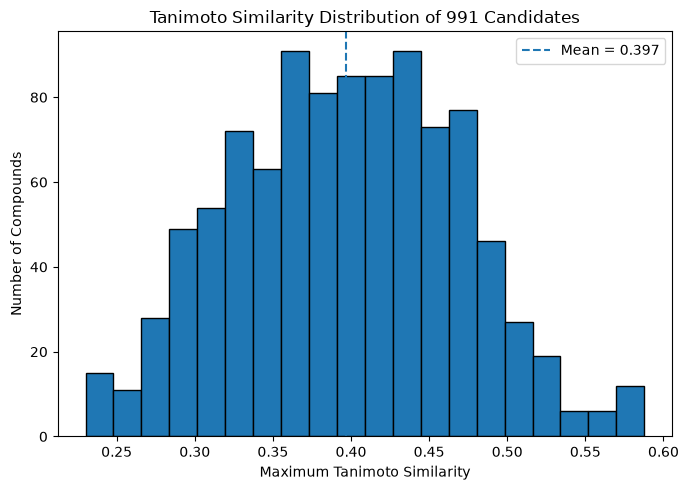

Mean similarity: 0.3965226846819927
Median similarity: 0.39743589743589236
SD similarity: 0.07191699759931222

Similarity distribution saved!


In [34]:

# ==========================================
# STEP 26: TANIMOTO SIMILARITY DISTRIBUTION
# ==========================================

import matplotlib.pyplot as plt
import numpy as np
import os

similarity_values = prediction_df[
    "Max_Tanimoto_Similarity"
].values

plt.figure(figsize=(7, 5))

plt.hist(
    similarity_values,
    bins=20,
    edgecolor="black"
)

plt.axvline(
    np.mean(similarity_values),
    linestyle="--",
    label=f"Mean = {np.mean(similarity_values):.3f}"
)

plt.xlabel("Maximum Tanimoto Similarity")
plt.ylabel("Number of Compounds")
plt.title("Tanimoto Similarity Distribution of 991 Candidates")

plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Tanimoto_Similarity_Distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Mean similarity:", np.mean(similarity_values))
print("Median similarity:", np.median(similarity_values))
print("SD similarity:", np.std(similarity_values))

print("\nSimilarity distribution saved!")


In [35]:

# ==========================================
# STEP 27: PRIORITY CANDIDATE SELECTION
# ==========================================

priority_df = prediction_df[
    (prediction_df["Predicted_pKd"] >= 4.0) &
    (prediction_df["Max_Tanimoto_Similarity"] >= 0.40)
].copy()

priority_df = priority_df.sort_values(
    by=["Predicted_pKd", "Max_Tanimoto_Similarity"],
    ascending=False
).reset_index(drop=True)

print("Total priority candidates:", len(priority_df))

display(priority_df.head(20))

# Save priority candidates
priority_df.to_csv(
    os.path.join(OUTPUT_DIR, "Priority_Candidates_SVR_Tanimoto.csv"),
    index=False
)

print("\nPriority candidates saved successfully!")


Total priority candidates: 81


,Compound ChEMBL ID,Smiles,Predicted_pKd,Predicted_Kd_uM,Max_Tanimoto_Similarity,Nearest_Training_ID,Nearest_Training_pKd
0,CHEMBL3786606,COCCS(=O)(=O)CCC(=O)N1C/C(=C\c2ccc(F)cc2)C(=O)...,4.430204,37.136101,0.439394,CHEMBL4455129,3.602060
1,CHEMBL4748146,O=C1/C(=C/c2ccc(F)cc2)CN(S(=O)(=O)c2ccccc2)C/C...,4.396114,40.168510,0.472527,CHEMBL4446091,3.309804
2,CHEMBL3314675,COc1ccc(/C=C2\CS(=O)(=O)C/C(=C/c3ccc(OC)c(F)c3...,4.281318,52.321694,0.437500,CHEMBL4218728,3.958607
3,CHEMBL3926457,COc1ccc(/C=C2\CC(C(=O)N3CCOCC3)C/C(=C\c3ccc(OC...,4.272330,53.415778,0.469697,CHEMBL4455129,3.602060
4,CHEMBL1773418,COc1ccc(/C=C2\CN(C(=O)CCSCCO)C/C(=C\c3ccc(OC)c...,4.247871,56.510532,0.486111,CHEMBL4455129,3.602060
5,CHEMBL4637754,COc1ccc(/C=C2\CN(C(=O)C(Cl)Cl)C/C(=C\c3ccc(OC)...,4.237167,57.920643,0.449275,CHEMBL4455129,3.602060
6,CHEMBL3985200,CCN(CC)CCNC(=O)C1C/C(=C\c2ccc(F)cc2)C(=O)/C(=C...,4.235665,58.121280,0.410959,CHEMBL4455129,3.602060
7,CHEMBL3410527,COc1ccc(/C=C2\CS(=O)(=O)C/C(=C\c3ccc(OC)cc3)C2...,4.216793,60.702552,0.422535,CHEMBL4435581,3.721246
8,CHEMBL3786853,COCC[S+]([O-])CCC(=O)N1C/C(=C\c2ccccc2)C(=O)/C...,4.215563,60.874660,0.425287,CHEMBL4446091,3.309804
9,CHEMBL3786079,COCCS(=O)(=O)CCC(=O)N1C/C(=C\c2ccccc2)C(=O)/C(...,4.211544,61.440617,0.422535,CHEMBL4435581,3.721246



Priority candidates saved successfully!


In [36]:

# ==========================================
# STEP 28: CANDIDATE CLASSIFICATION
# ==========================================

def classify_candidate(pk):
    if pk >= 4.3:
        return "High"
    elif pk >= 4.0:
        return "Moderate"
    else:
        return "Below threshold"

prediction_df["Predicted_Category"] = (
    prediction_df["Predicted_pKd"].apply(classify_candidate)
)

category_summary = (
    prediction_df["Predicted_Category"]
    .value_counts()
    .reindex(["High", "Moderate", "Below threshold"], fill_value=0)
    .reset_index()
)

category_summary.columns = ["Category", "Number_of_Compounds"]

display(category_summary)

category_summary.to_csv(
    os.path.join(OUTPUT_DIR, "Candidate_Category_Summary.csv"),
    index=False
)

# Save categorized predictions
prediction_df.to_csv(
    os.path.join(OUTPUT_DIR, "All_Candidates_Categorized.csv"),
    index=False
)

print("Candidate classification completed!")


,Category,Number_of_Compounds
0,High,17
1,Moderate,185
2,Below threshold,789


Candidate classification completed!


In [37]:

# ==========================================
# STEP 29: EXTRACT HIGH-PRIORITY CANDIDATES
# ==========================================

high_candidates = prediction_df[
    prediction_df["Predicted_pKd"] >= 4.3
].copy()

high_candidates = high_candidates.sort_values(
    by="Predicted_pKd",
    ascending=False
).reset_index(drop=True)

display(
    high_candidates[
        [
            "Compound ChEMBL ID",
            "Smiles",
            "Predicted_pKd",
            "Predicted_Kd_uM",
            "Max_Tanimoto_Similarity",
            "Nearest_Training_ID"
        ]
    ]
)

high_candidates.to_csv(
    os.path.join(OUTPUT_DIR, "High_Candidates_17.csv"),
    index=False
)

print("Total high candidates:", len(high_candidates))
print("File saved successfully!")


,Compound ChEMBL ID,Smiles,Predicted_pKd,Predicted_Kd_uM,Max_Tanimoto_Similarity,Nearest_Training_ID
0,CHEMBL4745370,O=C1/C(=C/c2ccc(F)cc2)CN(S(=O)(=O)c2ccc(F)cc2)...,4.573718,26.685902,0.312500,CHEMBL4435581
1,CHEMBL4162212,N#Cc1ccc(/C=C2\CN(S(=O)(=O)c3ccc(F)cc3)C/C(=C\...,4.570109,26.908568,0.365854,CHEMBL5285743
2,CHEMBL4764765,N#Cc1ccc(S(=O)(=O)N2C/C(=C\c3ccc(F)cc3)C(=O)/C...,4.570109,26.908568,0.280702,CHEMBL5283991
3,CHEMBL3935368,COc1ccc(/C=C2\CC(C(=O)N3CCN(C(C)=O)CC3)C/C(=C\...,4.494097,32.055547,0.270270,CHEMBL1450722
4,CHEMBL3786606,COCCS(=O)(=O)CCC(=O)N1C/C(=C\c2ccc(F)cc2)C(=O)...,4.430204,37.136101,0.439394,CHEMBL4455129
5,CHEMBL3786529,COCC[S+]([O-])CCC(=O)N1C/C(=C\c2ccc(F)cc2)C(=O...,4.428000,37.324980,0.350877,CHEMBL4443420
6,CHEMBL4755731,O=C1/C(=C/c2cccc(F)c2)CN(S(=O)(=O)c2ccc(F)cc2)...,4.418153,38.180996,0.368421,CHEMBL5426708
7,CHEMBL3940169,C=CCc1cc(/C=C2\CN(S(=O)(=O)CCC)C/C(=C\c3ccc(O)...,4.405113,39.344762,0.363636,CHEMBL5284407
8,CHEMBL4165653,O=C1/C(=C/c2ccccc2F)CN(S(=O)(=O)c2ccc(F)cc2)C/...,4.404015,39.444359,0.333333,CHEMBL4435581
9,CHEMBL4165172,N#Cc1ccc(/C=C2\CN(S(=O)(=O)c3ccc(F)cc3)C/C(=C\...,4.403469,39.493962,0.236842,CHEMBL5276559


Total high candidates: 17
File saved successfully!


In [38]:

# ==========================================
# STEP 30: HIGH CONFIDENCE CANDIDATES
# ==========================================

high_confidence = high_candidates[
    high_candidates["Max_Tanimoto_Similarity"] >= 0.40
].copy()

high_confidence = high_confidence.sort_values(
    by="Predicted_pKd",
    ascending=False
).reset_index(drop=True)

display(high_confidence)

high_confidence.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "High_Confidence_Candidates.csv"
    ),
    index=False
)

print("Total high confidence candidates:", len(high_confidence))
print("Results saved successfully!")


,Compound ChEMBL ID,Smiles,Predicted_pKd,Predicted_Kd_uM,Max_Tanimoto_Similarity,Nearest_Training_ID,Nearest_Training_pKd,Predicted_Category
0,CHEMBL3786606,COCCS(=O)(=O)CCC(=O)N1C/C(=C\c2ccc(F)cc2)C(=O)...,4.430204,37.136101,0.439394,CHEMBL4455129,3.602060,High
1,CHEMBL4748146,O=C1/C(=C/c2ccc(F)cc2)CN(S(=O)(=O)c2ccccc2)C/C...,4.396114,40.168510,0.472527,CHEMBL4446091,3.309804,High


Total high confidence candidates: 2
Results saved successfully!
